# Problem Statement
Fraud is rare, but missed fraudulent transactions can cause direct financial loss. This analysis compares ranking and classification behavior while preserving the natural class distribution in evaluation.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

SEED = 42
plt.style.use('seaborn-v0_8-whitegrid')
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
ROOT = Path.cwd()
DATA_CANDIDATES = [ROOT / 'creditcard.csv', ROOT.parent / 'creditcard.csv',
                   ROOT.parent.parent / 'creditcard.csv', ROOT / 'data' / 'creditcard.csv']
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Place creditcard.csv in this project root or its parent directory.')
OUT = ROOT if (ROOT / 'images').exists() else ROOT.parent
(OUT / 'images').mkdir(exist_ok=True)
(OUT / 'results').mkdir(exist_ok=True)

# Imports and Dataset Loading
The source contains anonymized PCA components, elapsed time, amount, and a binary fraud label. The dataset is not bundled with this project.

In [2]:
df = pd.read_csv(DATA_PATH)
required = {'Time', 'Amount', 'Class'} | {f'V{i}' for i in range(1, 29)}
assert required.issubset(df.columns), f'Missing columns: {required - set(df.columns)}'
assert set(df['Class'].unique()) <= {0, 1}, 'Class must be binary.'
print(f'Loaded: {DATA_PATH} | shape={df.shape}')
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum()}))
print(f'Duplicate rows: {df.duplicated().sum():,}')
display(df[['Time', 'Amount', 'Class']].describe().T)

Loaded: /Users/sameekshabhatia/Desktop/CDS 2023-25/ML projects/CreditcardFraud/creditcard.csv | shape=(284807, 31)


,dtype,missing
Time,float64,0
V1,float64,0
V2,float64,0
V3,float64,0
V4,float64,0
V5,float64,0
V6,float64,0
V7,float64,0
V8,float64,0
V9,float64,0


Duplicate rows: 1,081


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16
Class,284807.0,0.001727,0.041527,0.0,0.0,0.0,0.000,1.00


# Exploratory Data Analysis
The class plot uses counts and percentages. Amount is shown on a log-transformed axis to keep the long right tail visible.

,count,percent
Class,,
Genuine,284315,99.827251
Fraud,492,0.172749


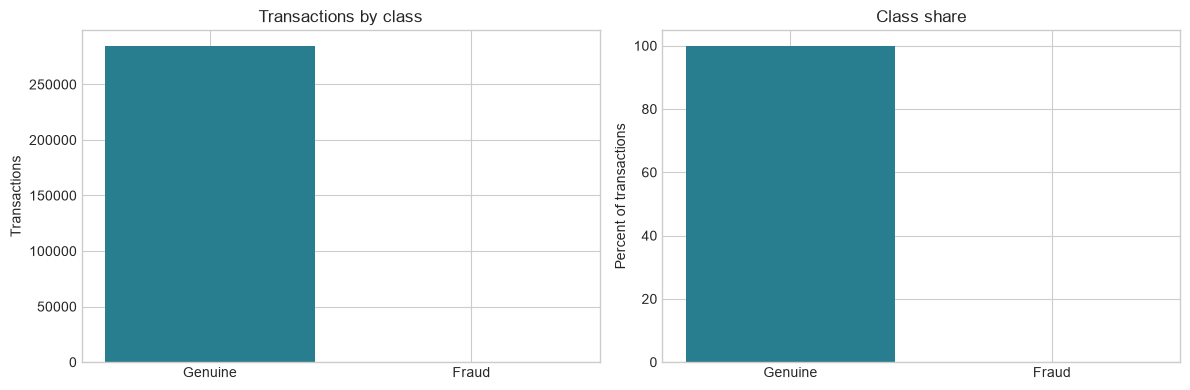

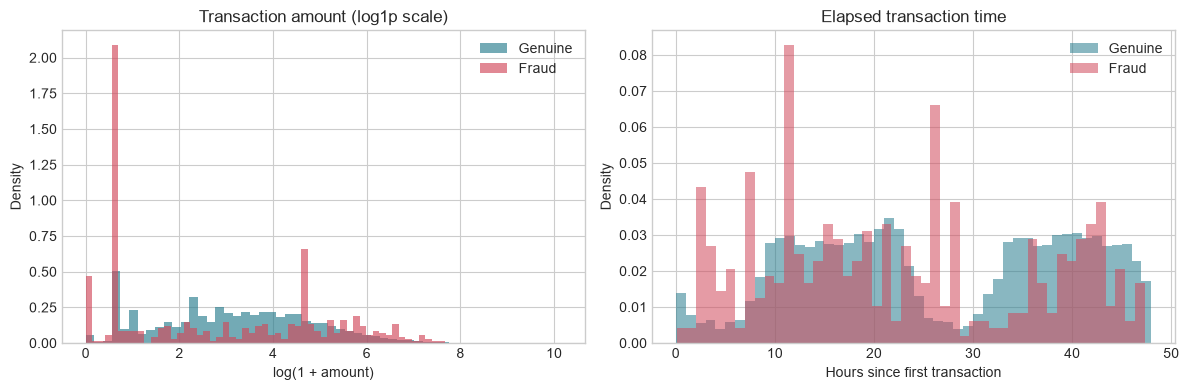

Amount                                    Time                      \
      median    mean     std  min       max   median      mean       std   
Class                                                                      
0      22.00   88.29  250.11  0.0  25691.16  84711.0  94838.20  47484.02   
1       9.25  122.21  256.68  0.0   2125.87  75568.5  80746.81  47835.37   

                        
         min       max  
Class                   
0        0.0  172792.0  
1      406.0  170348.0

In [3]:
class_summary = df['Class'].value_counts().sort_index().rename(index={0: 'Genuine', 1: 'Fraud'}).to_frame('count')
class_summary['percent'] = class_summary['count'] / len(df) * 100
display(class_summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = df['Class'].value_counts().sort_index()
axes[0].bar(['Genuine', 'Fraud'], counts.values, color=['#287D8E', '#D1495B'])
axes[0].set(title='Transactions by class', ylabel='Transactions')
axes[1].bar(['Genuine', 'Fraud'], counts.values / len(df) * 100, color=['#287D8E', '#D1495B'])
axes[1].set(title='Class share', ylabel='Percent of transactions')
fig.tight_layout()
fig.savefig(OUT / 'images' / 'class_distribution.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, name, color in [(0, 'Genuine', '#287D8E'), (1, 'Fraud', '#D1495B')]:
    values = df.loc[df['Class'].eq(label), 'Amount']
    axes[0].hist(np.log1p(values), bins=55, alpha=0.65, density=True, label=name, color=color)
    values_time = df.loc[df['Class'].eq(label), 'Time'] / 3600
    axes[1].hist(values_time, bins=48, alpha=0.55, density=True, label=name, color=color)
axes[0].set(title='Transaction amount (log1p scale)', xlabel='log(1 + amount)', ylabel='Density')
axes[1].set(title='Elapsed transaction time', xlabel='Hours since first transaction', ylabel='Density')
for axis in axes: axis.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / 'images' / 'transaction_distributions.png', dpi=180, bbox_inches='tight')
plt.show()
display(df.groupby('Class')[['Amount', 'Time']].agg(['median', 'mean', 'std', 'min', 'max']).round(2))

# Train-Test Split
A stratified split is made before any fitting or resampling. The test partition remains naturally imbalanced and is used only for final scoring.

In [4]:
X_raw = df.drop(columns='Class').copy()
y = df['Class'].astype('int8')
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=SEED, stratify=y)
# A reproducible stratified training subset keeps the six-model comparison laptop-friendly.
X_train, _, y_train, _ = train_test_split(
    X_train_full, y_train_full, train_size=30_000, random_state=SEED, stratify=y_train_full)
print(f'Modeling subset: {X_train.shape}; untouched test: {X_test.shape}')
print(f'Train fraud rate: {y_train.mean():.4%}; test fraud rate: {y_test.mean():.4%}')
assert y_train.value_counts().min() > 5 and y_test.value_counts().min() > 5

Modeling subset: (30000, 30); untouched test: (56962, 30)
Train fraud rate: 0.1733%; test fraud rate: 0.1720%


# Preprocessing
The already transformed V-features are passed through unchanged. Amount is log-transformed and standardized; elapsed Time becomes cyclic hour-of-day features. Learned scaling is fitted only inside each training pipeline.

In [5]:
def add_time_cycle(frame):
    features = frame.drop(columns='Time').copy()
    hour = (frame['Time'].to_numpy() % 86_400) / 86_400 * 2 * np.pi
    features['hour_sin'] = np.sin(hour)
    features['hour_cos'] = np.cos(hour)
    return features

X_train = add_time_cycle(X_train)
X_test = add_time_cycle(X_test)
PCA_COLUMNS = [f'V{i}' for i in range(1, 29)]
TIME_COLUMNS = ['hour_sin', 'hour_cos']
PREPROCESSOR = ColumnTransformer(
    [('amount', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                          ('scale', StandardScaler())]), ['Amount']),
     ('components', 'passthrough', PCA_COLUMNS),
     ('time_cycle', 'passthrough', TIME_COLUMNS)],
    remainder='drop')

# Baseline Models
All models are trained on the original class distribution. A common preprocessing pipeline prevents scaling leakage. The SVM uses decision scores for ranking metrics.

In [6]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1500, random_state=SEED),
    'KNN': KNeighborsClassifier(n_neighbors=7, n_jobs=-1),
    'Linear SVM': LinearSVC(C=1.0, random_state=SEED, max_iter=5000),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, class_weight=None, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    'XGBoost': XGBClassifier(n_estimators=120, max_depth=4, learning_rate=0.08,
                            subsample=0.9, colsample_bytree=0.9, eval_metric='logloss',
                            n_jobs=-1, random_state=SEED),
}

def ranking_score(fitted, features):
    if hasattr(fitted, 'decision_function'):
        return fitted.decision_function(features)
    return fitted.predict_proba(features)[:, 1]

def metric_row(name, fitted, features, labels):
    scores = ranking_score(fitted, features)
    predictions = fitted.predict(features)
    return {'model': name, 'accuracy': accuracy_score(labels, predictions),
            'precision': precision_score(labels, predictions, zero_division=0),
            'fraud_recall': recall_score(labels, predictions, zero_division=0),
            'f1': f1_score(labels, predictions, zero_division=0),
            'roc_auc': roc_auc_score(labels, scores),
            'pr_auc': average_precision_score(labels, scores),
            'confusion_matrix': confusion_matrix(labels, predictions),
            'scores': scores}

baseline_pipelines = {}
baseline_rows = []
baseline_scores = {}
for name, estimator in models.items():
    fitted = Pipeline([('preprocess', PREPROCESSOR), ('model', estimator)])
    fitted.fit(X_train, y_train)
    baseline_pipelines[name] = fitted
    row = metric_row(name, fitted, X_test, y_test)
    baseline_rows.append({key: value for key, value in row.items() if key not in {'confusion_matrix', 'scores'}})
    baseline_scores[name] = row['scores']
baseline_metrics = pd.DataFrame(baseline_rows).sort_values('pr_auc', ascending=False)
display(baseline_metrics.round(4))
baseline_metrics.to_csv(OUT / 'results' / 'baseline_metrics.csv', index=False)


,model,accuracy,precision,fraud_recall,f1,roc_auc,pr_auc
4,Random Forest,0.9994,0.8523,0.7653,0.8065,0.9470,0.8327
5,XGBoost,0.9994,0.8427,0.7653,0.8021,0.9740,0.8313
2,Linear SVM,0.9993,0.8571,0.7347,0.7912,0.9447,0.7570
1,KNN,0.9993,0.8132,0.7551,0.7831,0.9335,0.7378
0,Logistic Regression,0.9992,0.7653,0.7653,0.7653,0.9540,0.7350
3,Decision Tree,0.9992,0.7653,0.7653,0.7653,0.8823,0.5861


# Baseline Evaluation
Accuracy is reported for context, but PR-AUC and fraud recall are more informative under this class ratio. Confusion matrices use each classifier's default decision rule.

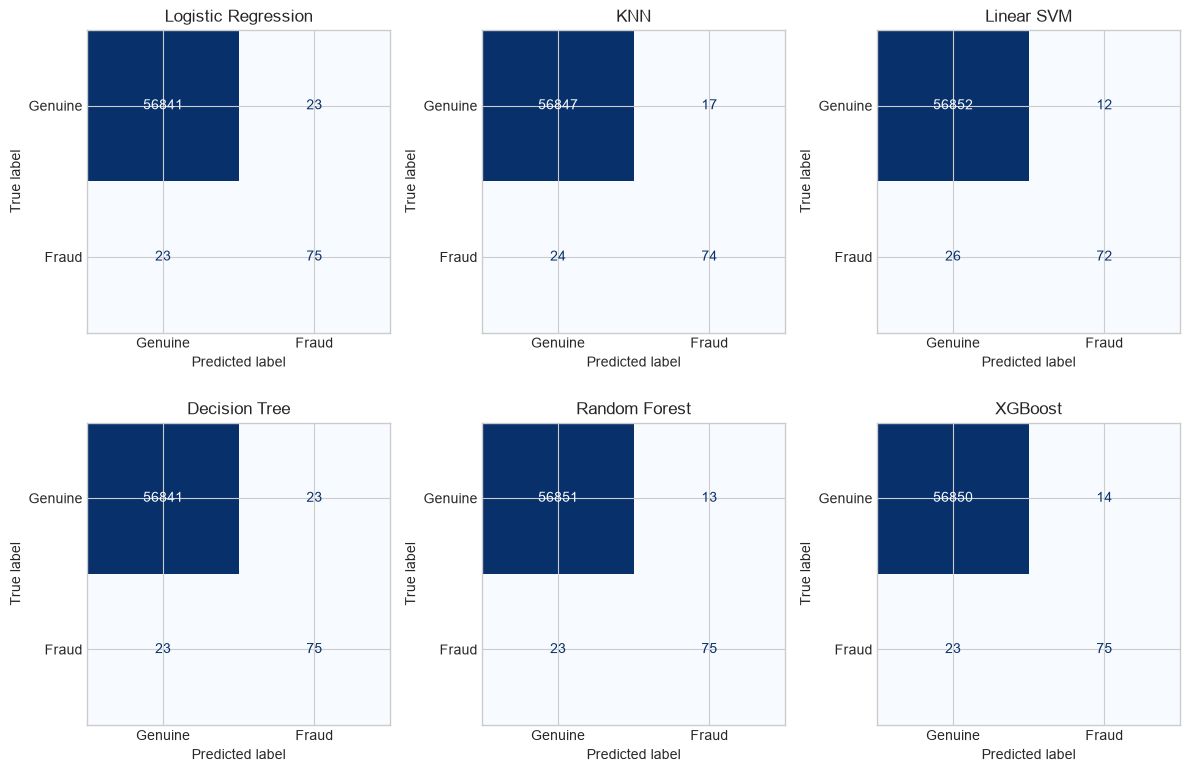

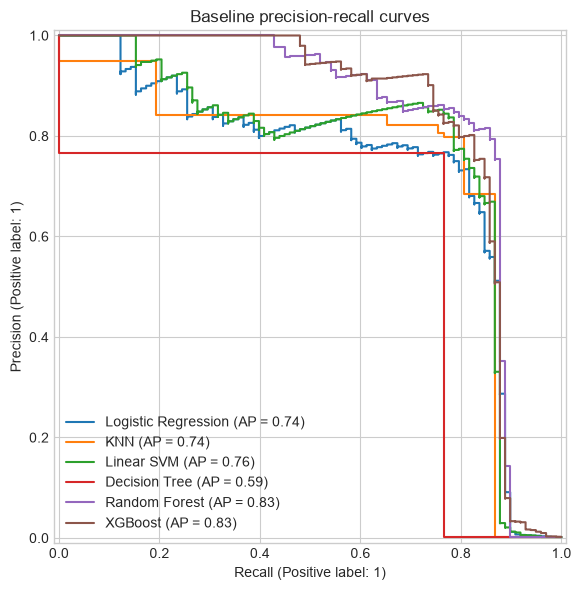

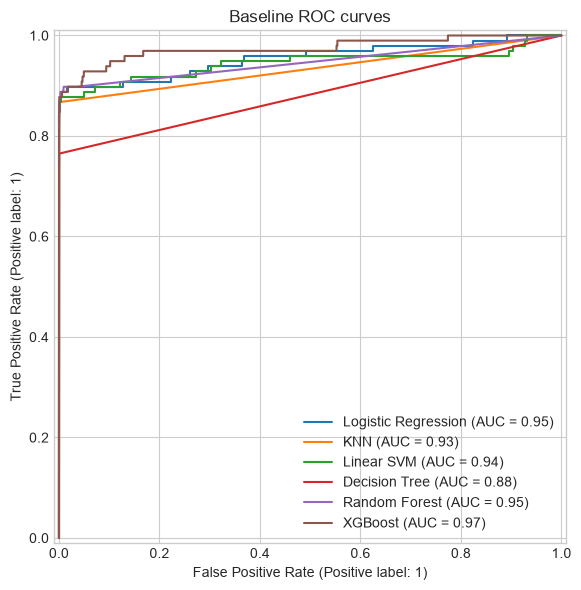

Logistic Regression: missed fraud cases (false negatives) = 23


KNN: missed fraud cases (false negatives) = 24
Linear SVM: missed fraud cases (false negatives) = 26
Decision Tree: missed fraud cases (false negatives) = 23
Random Forest: missed fraud cases (false negatives) = 23
XGBoost: missed fraud cases (false negatives) = 23


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for axis, (name, fitted) in zip(axes.flat, baseline_pipelines.items()):
    ConfusionMatrixDisplay.from_estimator(fitted, X_test, y_test,
        display_labels=['Genuine', 'Fraud'], cmap='Blues', colorbar=False, ax=axis, values_format='d')
    axis.set_title(name)
fig.tight_layout()
fig.savefig(OUT / 'images' / 'baseline_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axis = plt.subplots(figsize=(7, 6))
for name, scores in baseline_scores.items():
    PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=axis)
axis.set_title('Baseline precision-recall curves')
fig.tight_layout()
fig.savefig(OUT / 'images' / 'baseline_precision_recall.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axis = plt.subplots(figsize=(7, 6))
for name, scores in baseline_scores.items():
    RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=axis)
axis.set_title('Baseline ROC curves')
fig.tight_layout()
fig.savefig(OUT / 'images' / 'baseline_roc_curve.png', dpi=180, bbox_inches='tight')
plt.show()

for name, fitted in baseline_pipelines.items():
    prediction = fitted.predict(X_test)
    matrix = confusion_matrix(y_test, prediction)
    print(f'{name}: missed fraud cases (false negatives) = {matrix[1, 0]:,}')

# Findings
A model can achieve high accuracy by predicting the majority class, while detecting few frauds. Baseline false negatives and precision-recall behavior motivate the training-only sampling and threshold experiments in Notebook 2.